## DAY 13 — Exploratory Data Analysis and Business Questions 
## Task: 
Learn to convert business problems into analytical questions.

## 1. Select a sample sales or customer dataset. 

## Step 1: Import Libraries and Load Dataset

In [1]:

import pandas as pd

df = pd.read_csv("Day13_Customer_Shopping.csv")

df.head()


,Customer_ID,Age,Gender,City,Product,Quantity,Sales,Payment_Method
0,1001,22,Female,Nagpur,Laptop,1,55000,UPI
1,1002,35,Male,Pune,Mobile,2,30000,Credit Card
2,1003,28,Female,Mumbai,Headphones,1,2500,UPI
3,1004,42,Male,Nagpur,Tablet,1,18000,Debit Card
4,1005,31,Female,Pune,Mobile,1,15000,Cash



## Step 2: Inspect the Dataset


In [2]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types and missing values
df.info()

# Get basic statistical information
df.describe()


Dataset Shape: (30, 8)

Column Names:
Index(['Customer_ID', 'Age', 'Gender', 'City', 'Product', 'Quantity', 'Sales',
       'Payment_Method'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Customer_ID     30 non-null     int64
 1   Age             30 non-null     int64
 2   Gender          30 non-null     str  
 3   City            30 non-null     str  
 4   Product         30 non-null     str  
 5   Quantity        30 non-null     int64
 6   Sales           30 non-null     int64
 7   Payment_Method  30 non-null     str  
dtypes: int64(4), str(4)
memory usage: 2.1 KB


,Customer_ID,Age,Quantity,Sales
count,30.000000,30.000000,30.000000,30.000000
mean,1015.500000,33.100000,1.433333,24316.666667
std,8.803408,8.150947,0.626062,19903.423433
min,1001.000000,21.000000,1.000000,2500.000000
25%,1008.250000,27.000000,1.000000,7500.000000
50%,1015.500000,32.000000,1.000000,18500.000000
75%,1022.750000,38.750000,2.000000,33500.000000
max,1030.000000,51.000000,3.000000,62000.000000


## 2. Define five business questions. 

Business questions help us understand business performance and make data-driven decisions.

1. Which product generates the highest total sales?
2. Which city has the highest total sales?
3. Which payment method is used most frequently by customers?
4. Which gender contributes the highest total sales?
5. What is the average age of customers who make purchases?
    


##  3: Identify Metrics for Each Business Question

Metrics are measurable values used to analyze data and answer business questions.

| Business Question | Required Metric |
|---|---|
| 1. Which product generates the highest total sales? | Total sales by product |
| 2. Which city has the highest total sales? | Total sales by city |
| 3. Which payment method is used most frequently? | Number of transactions by payment method |
| 4. Which gender contributes the highest total sales? | Total sales by gender |
| 5. What is the average age of customers? | Average customer age |


## 4. Use Pandas, SQL, and visualizations to analyze the data. 

In [3]:
#Analyze Business Questions Using Pandas
#Question 1: Which product generates the highest total sales?


product_sales = df.groupby("Product")["Sales"].sum()

print("Total Sales by Product:")
print(product_sales)

print("\nProduct with Highest Sales:")
print(product_sales.idxmax())

print("Highest Total Sales:", product_sales.max())




Total Sales by Product:
Product
Headphones     30500
Laptop        351000
Mobile        175000
Smartwatch     37500
Tablet        135500
Name: Sales, dtype: int64

Product with Highest Sales:
Laptop
Highest Total Sales: 351000


- groupby()	 :-Groups data based on a specific column.
- sum()	    :-  Calculates the total of numerical values.
- idxmax()	:-Returns the name or label associated with the highest value.
-  max()	:-Returns the highest numerical value.

## Question 2: Which city has the highest total sales?

In [4]:

city_sales = df.groupby("City")["Sales"].sum()

print("Total Sales by City:")
print(city_sales)

print("\nCity with Highest Sales:")
print(city_sales.idxmax())

print("Highest Total Sales:", city_sales.max())


Total Sales by City:
City
Mumbai    212500
Nagpur    242000
Pune      275000
Name: Sales, dtype: int64

City with Highest Sales:
Pune
Highest Total Sales: 275000


## Question 3: Which payment method is used most frequently by customers?

In [5]:

payment_count = df.groupby("Payment_Method")["Customer_ID"].count()

print("Number of Purchases by Payment Method:")
print(payment_count)

print("\nMost Frequently Used Payment Method:")
print(payment_count.idxmax())

print("Highest Number of Purchases:", payment_count.max())


Number of Purchases by Payment Method:
Payment_Method
Cash           5
Credit Card    9
Debit Card     7
UPI            9
Name: Customer_ID, dtype: int64

Most Frequently Used Payment Method:
Credit Card
Highest Number of Purchases: 9


groupby() — Groups data based on a specific column.



count() — Counts the number of non-missing values.



idxmax() — Returns the label with the highest value.



max() — Returns the highest numerical value.

## Question 4: Which gender contributes the highest total sales?

In [6]:

gender_sales = df.groupby("Gender")["Sales"].sum()

print("Total Sales by Gender:")
print(gender_sales)

print("\nGender with Highest Sales:")
print(gender_sales.idxmax())

print("Highest Total Sales:", gender_sales.max())


Total Sales by Gender:
Gender
Female    339000
Male      390500
Name: Sales, dtype: int64

Gender with Highest Sales:
Male
Highest Total Sales: 390500


## Question 5: What is the average age of customers who make purchases?

In [7]:

average_age = df["Age"].mean()

print("Average Customer Age:", average_age)

#mean() — Calculates the average of numerical values.

Average Customer Age: 33.1


## Analyze Business Questions Using SQL

In [8]:

import sqlite3

# Create a database connection
conn = sqlite3.connect("Day13_EDA.db")

# Load the dataset into an SQL table
df.to_sql("Customer_Shopping", conn, if_exists="replace", index=False)

print("Dataset loaded into SQLite database successfully!")


Dataset loaded into SQLite database successfully!


- sqlite3 — Python library used to work with SQLite databases.



- connect() — Creates a connection to the database.



- to_sql() — Stores a Pandas DataFrame in an SQL table.



- if_exists="replace" — Replaces the table if it already exists.



- index=False — Does not save the Pandas row index as an extra column.

In [9]:
#Question 1 — Which product generates the highest total sales?

query = """
SELECT Product, SUM(Sales) AS Total_Sales
FROM Customer_Shopping
GROUP BY Product
ORDER BY Total_Sales DESC;
"""

pd.read_sql_query(query, conn)


,Product,Total_Sales
0,Laptop,351000
1,Mobile,175000
2,Tablet,135500
3,Smartwatch,37500
4,Headphones,30500


- SELECT	:-Specifies the columns to display.
- SUM()	    :-Calculates the total of numerical values.
- AS	    :-Gives a temporary name to a column or result.
- FROM	    :-Specifies the table from which data is retrieved.
- GROUP BY	 :-Groups rows with the same value.
- ORDER BY	:-Sorts the results.
- DESC	:-Sorts values in descending order, highest to lowest.
- pd.read_sql_query() :- executes the SQL query and displays its result as a Pandas DataFrame.

In [10]:
#Question 2: Which city has the highest total sales?

query = """
SELECT City, SUM(Sales) AS Total_Sales
FROM Customer_Shopping
GROUP BY City
ORDER BY Total_Sales DESC;
"""

pd.read_sql_query(query, conn)


,City,Total_Sales
0,Pune,275000
1,Nagpur,242000
2,Mumbai,212500


- SUM(Sales) — Calculates total sales.



- GROUP BY City — Groups sales by city.



- ORDER BY Total_Sales DESC — Arranges cities from highest to lowest total sales.

In [11]:
#Question 3: Which payment method is used most frequently by customers?

query = """
SELECT Payment_Method, COUNT(*) AS Total_Purchases
FROM Customer_Shopping
GROUP BY Payment_Method
ORDER BY Total_Purchases DESC;
"""

pd.read_sql_query(query, conn)


,Payment_Method,Total_Purchases
0,UPI,9
1,Credit Card,9
2,Debit Card,7
3,Cash,5


COUNT(*) — Counts the number of rows in each group.



GROUP BY Payment_Method — Groups records by payment method.



ORDER BY Total_Purchases DESC — Sorts the results from highest to lowest.

In [12]:
#Question 4: Which gender contributes the highest total sales?

query = """
SELECT Gender, SUM(Sales) AS Total_Sales
FROM Customer_Shopping
GROUP BY Gender
ORDER BY Total_Sales DESC;
"""

pd.read_sql_query(query, conn)


,Gender,Total_Sales
0,Male,390500
1,Female,339000


In [13]:
#Question 5: What is the average age of customers?

query = """
SELECT AVG(Age) AS Average_Customer_Age
FROM Customer_Shopping;
"""

pd.read_sql_query(query, conn)


,Average_Customer_Age
0,33.1


AVG() — Calculates the average of numerical values.



AS — Gives a name to the resulting column.

## Data Visualization

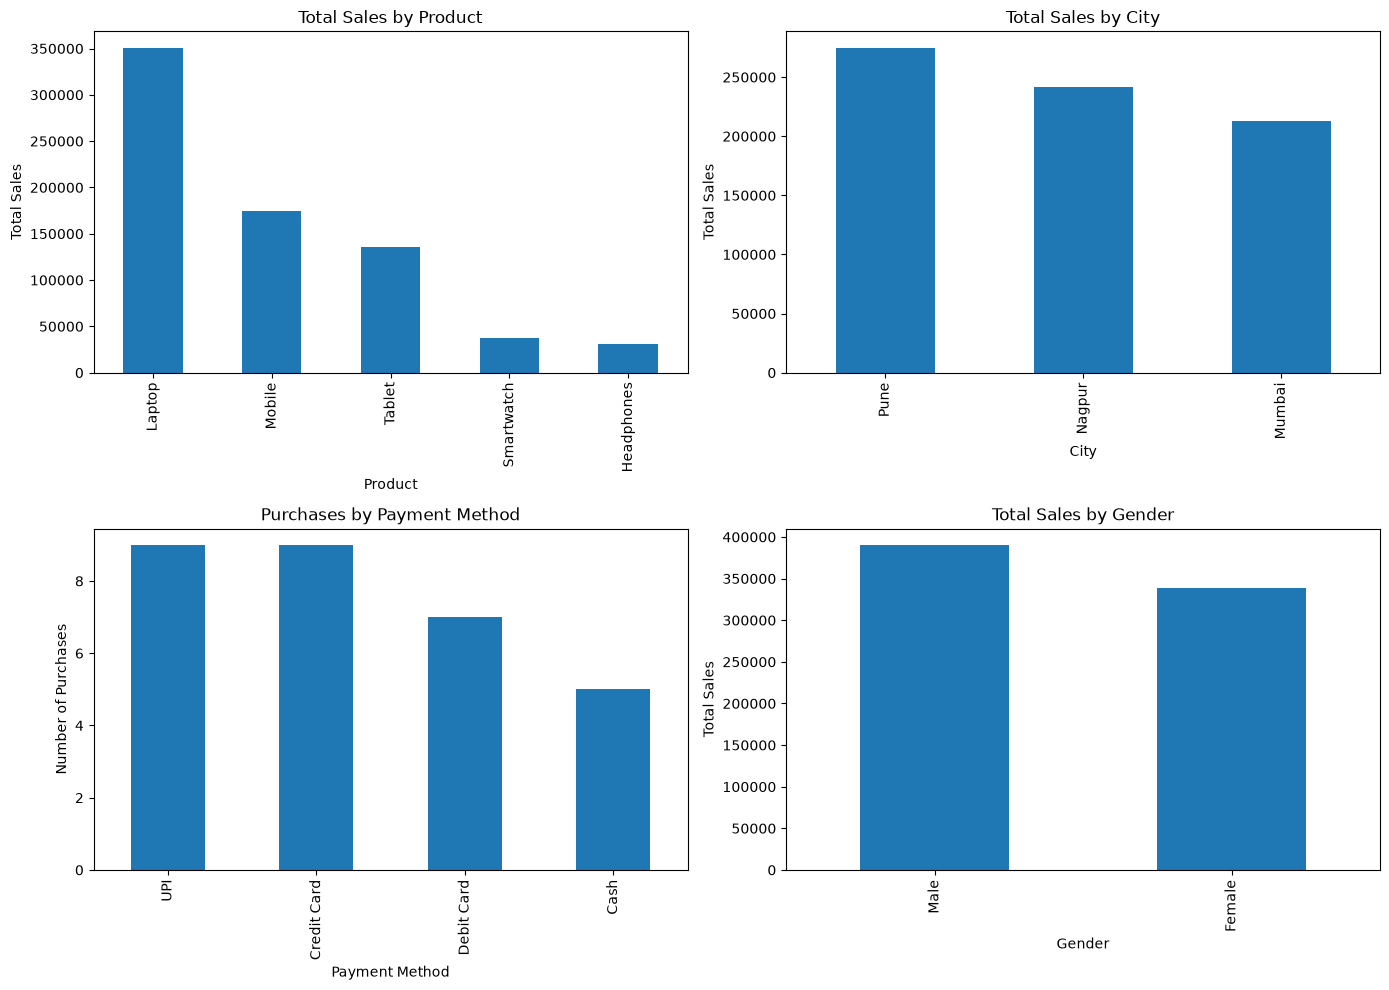

Average Customer Age: 33.1 years


In [14]:

import matplotlib.pyplot as plt

# 1. Total Sales by Product
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

# 2. Total Sales by City
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False)

# 3. Purchases by Payment Method
payment_count = df["Payment_Method"].value_counts().sort_values(ascending=False)

# 4. Total Sales by Gender
gender_sales = df.groupby("Gender")["Sales"].sum().sort_values(ascending=False)

# 5. Average Customer Age
average_age = df["Age"].mean()

# Create all visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

product_sales.plot(kind="bar", ax=axes[0, 0], title="Total Sales by Product")
axes[0, 0].set_xlabel("Product")
axes[0, 0].set_ylabel("Total Sales")

city_sales.plot(kind="bar", ax=axes[0, 1], title="Total Sales by City")
axes[0, 1].set_xlabel("City")
axes[0, 1].set_ylabel("Total Sales")

payment_count.plot(kind="bar", ax=axes[1, 0], title="Purchases by Payment Method")
axes[1, 0].set_xlabel("Payment Method")
axes[1, 0].set_ylabel("Number of Purchases")

gender_sales.plot(kind="bar", ax=axes[1, 1], title="Total Sales by Gender")
axes[1, 1].set_xlabel("Gender")
axes[1, 1].set_ylabel("Total Sales")

plt.tight_layout()
plt.show()

print("Average Customer Age:", round(average_age, 2), "years")



- matplotlib.pyplot	:-Used to create visualizations in Python.
- groupby()	         :-Groups data based on a specific column.
- sum()	            :-Calculates the total of numerical values.
- sort_values()	       :-Sorts values in ascending or descending order.
- value_counts()	:-Counts how many times each value occurs.
- mean()	      :-Calculates the average value.
- plot()	       :-Creates a chart from data.
- kind="bar"	:-Specifies that a bar chart should be created.
- subplots()	:-Creates multiple plots in one figure.
- set_xlabel()	:-Sets the label of the X-axis.
- set_ylabel()	:-Sets the label of the Y-axis.
- tight_layout()	:-Adjusts spacing between charts.
- show()	         :-Displays the visualizations.
- round()	        :-Rounds a numerical value to a specified number of decimal places.

## Findings
1. Product Sales: Laptop generates the highest total sales of ₹351,000.
2. City Sales: Pune has the highest total sales of ₹275,000.
3. Payment Method: UPI and Credit Card are tied, with 9 purchases each.
4. Gender Sales: Male customers contribute the highest total sales of ₹390,500.
5. Average Customer Age: The average customer age is 33.1 years.
## Limitations
1. The dataset contains only 30 records, so the findings may not represent all customers.
2. The dataset includes only three cities and five product categories.
3. The dataset does not contain a date column, so sales trends over time cannot be analyzed.
4. The findings are based only on the available dataset and may not apply to a larger customer population.